# Data Exploration

In [11]:
import torch
import torchvision
from torchvision.datasets import GTSRB

import numpy  as np
import matplotlib.pyplot as plt

from collections import Counter
from pathlib import Path

In [12]:
import pandas as pd
from pathlib import Path

data_dir = Path("D:\\University Documents\\UOM\\Semester 05\\PR\\project_v1\\data\\raw\\gtsrb")


train_csv = pd.read_csv(data_dir / "Train.csv")

print(train_csv.shape)
train_csv.head()

(39209, 8)


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [13]:
print(train_csv["ClassId"].nunique())
print(train_csv["ClassId"].value_counts().sort_index())

43
ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     390
23     510
24     270
25    1500
26     600
27     240
28     540
29     270
30     450
31     780
32     240
33     689
34     420
35    1200
36     390
37     210
38    2070
39     300
40     360
41     240
42     240
Name: count, dtype: int64


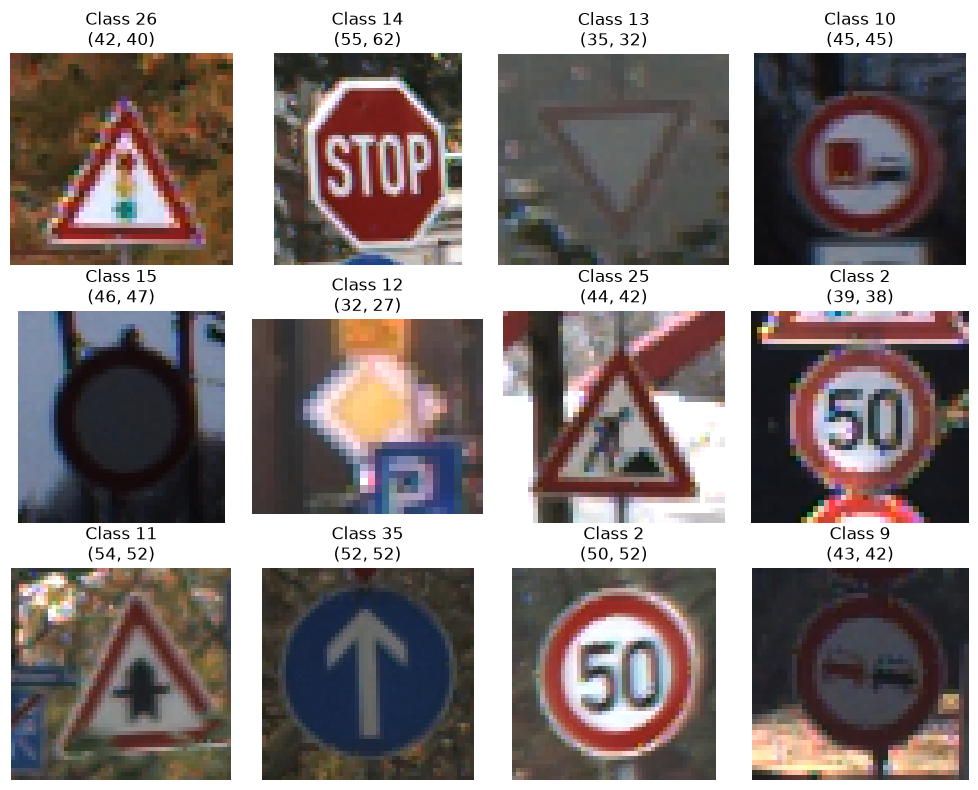

In [14]:
import matplotlib.pyplot as plt
from PIL import Image

# Randomly choose 12 training examples
samples = train_csv.sample(12, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    
    img_path = data_dir / row["Path"]
    img = Image.open(img_path)

    ax.imshow(img)
    ax.set_title(f"Class {row['ClassId']}\n{img.size}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
import pandas as pd
from pathlib import Path

data_dir = Path("D:\\University Documents\\UOM\\Semester 05\\PR\\project_v1\\data\\raw\\gtsrb")
train_csv = pd.read_csv(data_dir / "Train.csv")
test_csv  = pd.read_csv(data_dir / "Test.csv")

all_df = pd.concat([train_csv, test_csv], ignore_index=True)

print("Total images:", len(all_df))
print("Number of classes:", all_df["ClassId"].nunique())

Total images: 51839
Number of classes: 43


## Test Train Split

In [16]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    all_df,
    test_size=0.30,
    random_state=42,
    stratify=all_df["ClassId"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["ClassId"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 36287
Validation: 7776
Test: 7776


In [17]:
n = len(all_df)

print(f"Train: {len(train_df)/n:.2%}")
print(f"Validation: {len(val_df)/n:.2%}")
print(f"Test: {len(test_df)/n:.2%}")

Train: 70.00%
Validation: 15.00%
Test: 15.00%


## Resizing and Padding

In [18]:
from PIL import Image, ImageOps
from torchvision import transforms

class ResizeAndPad:
    def __init__(self, size = (32,32)):
        self.size = size
    def __call__(self, image):
        return ImageOps.pad(
            image, 
            self.size,
            method = Image.Resampling.BILINEAR,
            color = (0,0,0),
            centering = (0.5, 0.5, 0.5)
        )

In [19]:
from torch.utils.data import Dataset
class GTSRBDataset(Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_path = self.root_dir / row["Path"]

        image = Image.open(img_path).convert("RGB")
        label = int(row["ClassId"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [20]:
transform = transforms.Compose([
    ResizeAndPad((32, 32)),
    transforms.ToTensor()
])


In [21]:
train_dataset = GTSRBDataset(
    train_df,
    data_dir,
    transform=transform
)

val_dataset = GTSRBDataset(
    val_df,
    data_dir,
    transform=transform
)

test_dataset = GTSRBDataset(
    test_df,
    data_dir,
    transform=transform
)

In [22]:
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

36287
7776
7776


In [23]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [24]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([64, 3, 32, 32])
Labels: torch.Size([64])


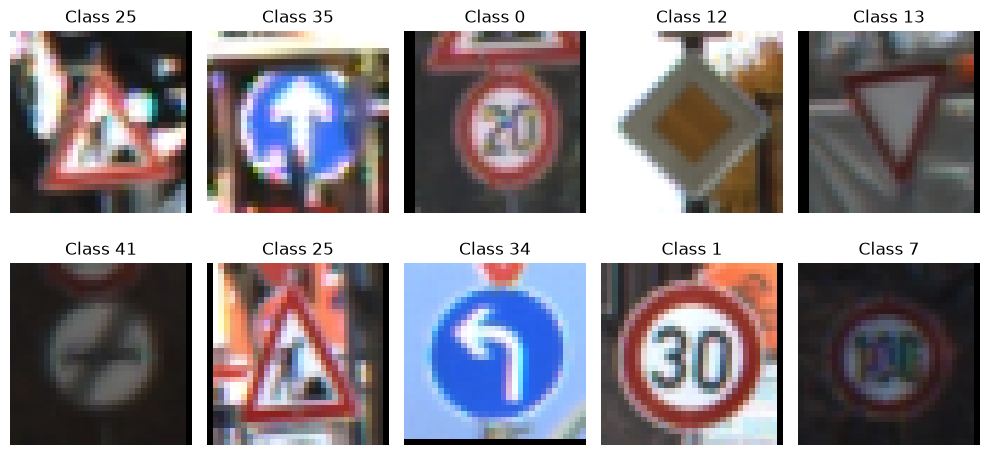

In [25]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.ravel()):
    img = images[i].permute(1, 2, 0)

    ax.imshow(img)
    ax.set_title(f"Class {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Normalizing the Data

In [26]:
import torch

channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
num_pixels = 0

for images, _ in train_loader:
    # images shape: [B, C, H, W]
    channel_sum += images.sum(dim=[0, 2, 3]) #summing accross all 64 images, channel by channel
    channel_sum_sq += (images ** 2).sum(dim=[0, 2, 3])

    num_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / num_pixels
std = torch.sqrt(channel_sum_sq / num_pixels - mean ** 2)

print("Mean:", mean)
print("Std :", std)

Mean: tensor([0.3219, 0.2955, 0.3048])
Std : tensor([0.2742, 0.2621, 0.2689])


New Transform including the normalization

In [27]:
transform = transforms.Compose([
    ResizeAndPad((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [28]:
train_dataset = GTSRBDataset(train_df, data_dir, transform = transform)
val_dataset = GTSRBDataset(val_df,data_dir, transform= transform)
test_dataset = GTSRBDataset(test_df, data_dir, transform = transform)


In [29]:
train_transform = transforms.Compose([
    ResizeAndPad((32, 32)),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=mean,
        std=std
    )
])

In [30]:
eval_transform = transforms.Compose([
    ResizeAndPad((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean,
        std=std
    )
])

In [31]:
train_dataset = GTSRBDataset(
    train_df,
    data_dir,
    transform=train_transform
)

val_dataset = GTSRBDataset(
    val_df,
    data_dir,
    transform=eval_transform
)

test_dataset = GTSRBDataset(
    test_df,
    data_dir,
    transform=eval_transform
)

In [32]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

## CNN Model A

In [33]:
from torch import nn

class LeNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=6,
            kernel_size=5
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.conv2 = nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5
        )

        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 43)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [34]:
model_a = LeNet()
print(model_a)

LeNet(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=43, bias=True)
  (relu): ReLU()
)


In [35]:
images, labels = next(iter(train_loader))

print("Input:", images.shape)

outputs = model_a(images)

print("Output:", outputs.shape)

Input: torch.Size([64, 3, 32, 32])
Output: torch.Size([64, 43])


In [36]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)

Using: cpu


d:\University Documents\UOM\Semester 05\IP\assignment_01\.venv\Lib\site-packages\torch\cuda\__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 11070). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10\cuda\CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [37]:
model_a = model_a.to(device)

In [38]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_a.parameters(),
    lr=0.001
)

In [39]:
num_epochs = 20

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    model_a.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Remove gradients from previous batch
        optimizer.zero_grad()

        # Forward pass
        outputs = model_a(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Predictions
        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = correct / total

    # -------------------------
    # Validation
    # -------------------------
    model_a.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_a(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader.dataset)
    val_acc = correct / total

    # Store results
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch+1:2d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/20 | Train Loss: 1.5455 | Train Acc: 0.5550 | Val Loss: 0.6231 | Val Acc: 0.8270
Epoch  2/20 | Train Loss: 0.4687 | Train Acc: 0.8615 | Val Loss: 0.2963 | Val Acc: 0.9172
Epoch  3/20 | Train Loss: 0.2663 | Train Acc: 0.9220 | Val Loss: 0.2012 | Val Acc: 0.9479
Epoch  4/20 | Train Loss: 0.1904 | Train Acc: 0.9458 | Val Loss: 0.1374 | Val Acc: 0.9651
Epoch  5/20 | Train Loss: 0.1461 | Train Acc: 0.9570 | Val Loss: 0.1719 | Val Acc: 0.9522
Epoch  6/20 | Train Loss: 0.1184 | Train Acc: 0.9656 | Val Loss: 0.1039 | Val Acc: 0.9766
Epoch  7/20 | Train Loss: 0.0989 | Train Acc: 0.9712 | Val Loss: 0.0992 | Val Acc: 0.9766
Epoch  8/20 | Train Loss: 0.0888 | Train Acc: 0.9736 | Val Loss: 0.1164 | Val Acc: 0.9712
Epoch  9/20 | Train Loss: 0.0739 | Train Acc: 0.9780 | Val Loss: 0.0936 | Val Acc: 0.9765
Epoch 10/20 | Train Loss: 0.0725 | Train Acc: 0.9773 | Val Loss: 0.0881 | Val Acc: 0.9796
Epoch 11/20 | Train Loss: 0.0616 | Train Acc: 0.9809 | Val Loss: 0.0857 | Val Acc: 0.9823
Epoch 12/2

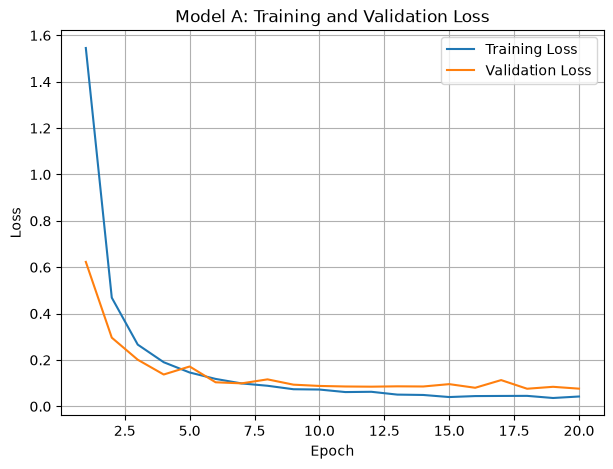

In [40]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(7, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A: Training and Validation Loss")
plt.legend()
plt.grid()

plt.show()

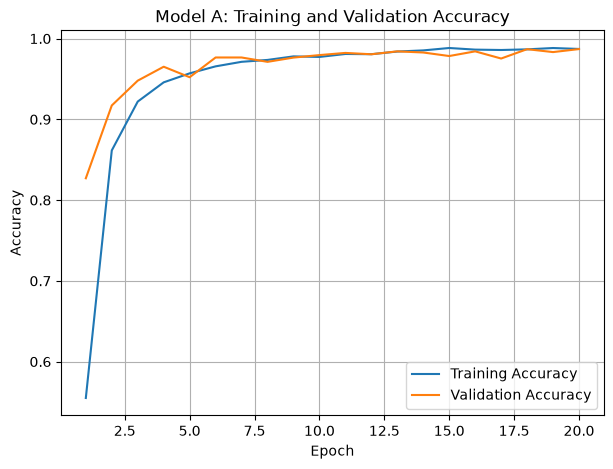

In [41]:
plt.figure(figsize=(7, 5))

plt.plot(epochs, train_accuracies, label="Training Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A: Training and Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

In [42]:
model_a.eval()

test_loss = 0.0
correct = 0
total = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_a(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

test_loss = test_loss / len(test_loader.dataset)
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.0836
Test Accuracy: 0.9847


In [43]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score
)

cm = confusion_matrix(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print("Weighted Precision:", precision)
print("Weighted Recall:", recall)

Weighted Precision: 0.9848914607830135
Weighted Recall: 0.9846965020576132


In [44]:
macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro"
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro"
)

print("Macro Precision:", macro_precision)
print("Macro Recall:", macro_recall)

Macro Precision: 0.9870419330695424
Macro Recall: 0.9797612157898492


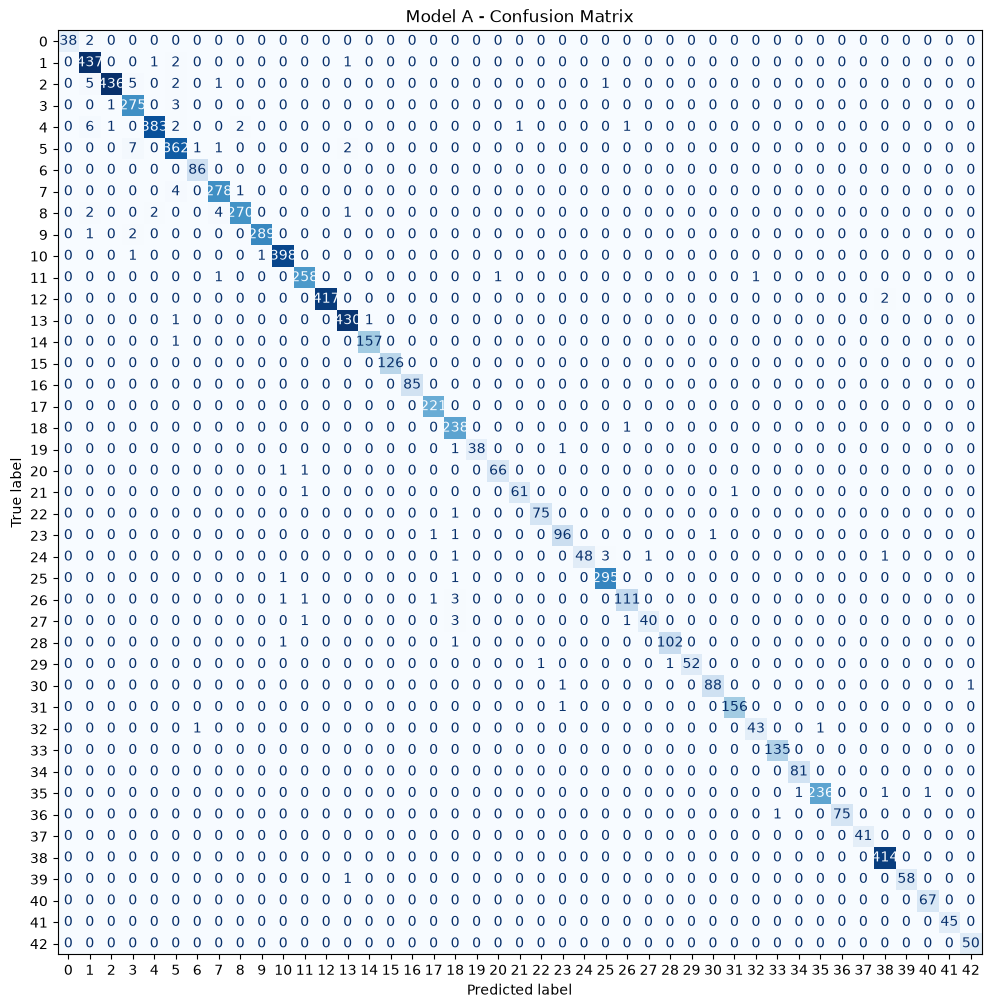

In [45]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(12, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.title("Model A - Confusion Matrix")
plt.show()

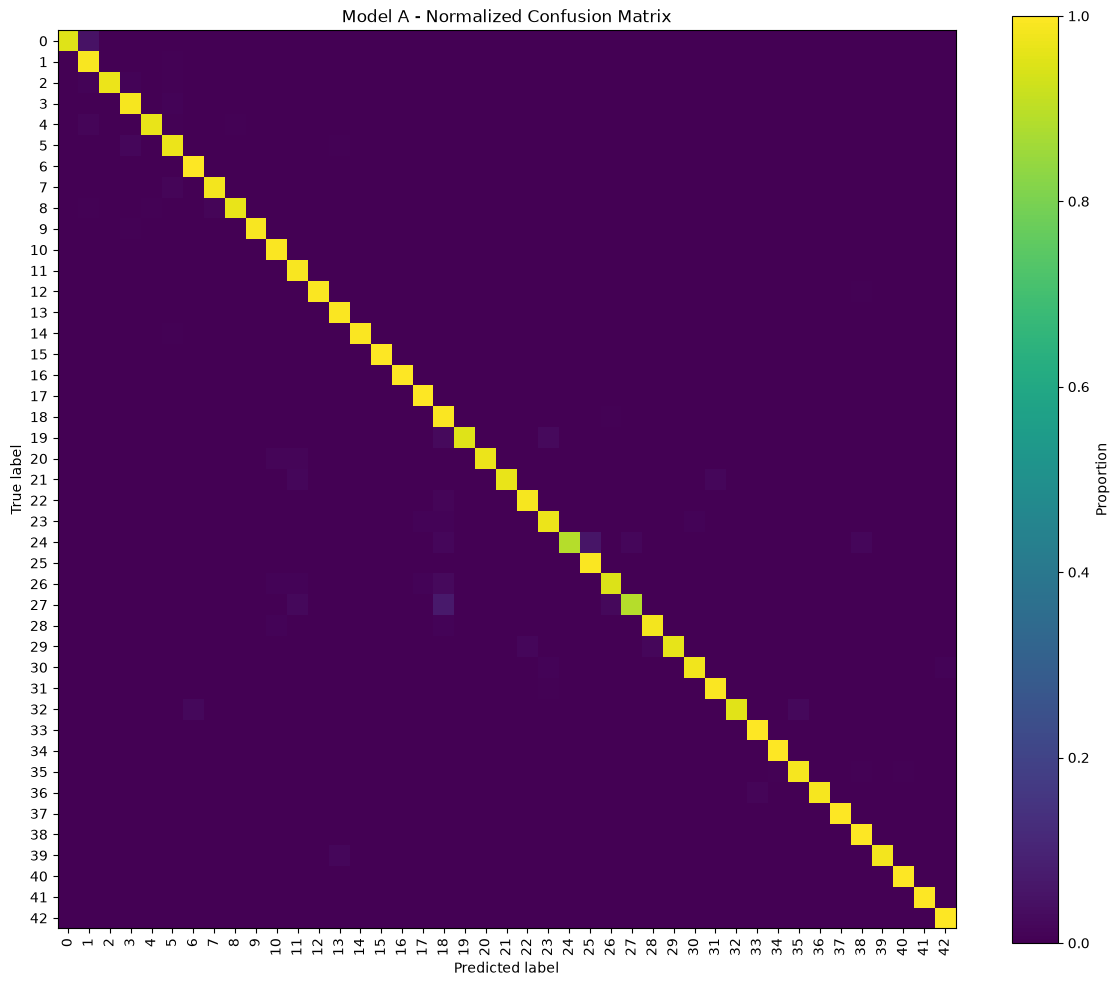

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_norm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize="true"
)

plt.figure(figsize=(12, 10))

plt.imshow(cm_norm, interpolation="nearest")
plt.title("Model A - Normalized Confusion Matrix")

plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.xticks(range(43), range(43), rotation=90)
plt.yticks(range(43), range(43))

plt.colorbar(label="Proportion")

plt.tight_layout()
plt.show()

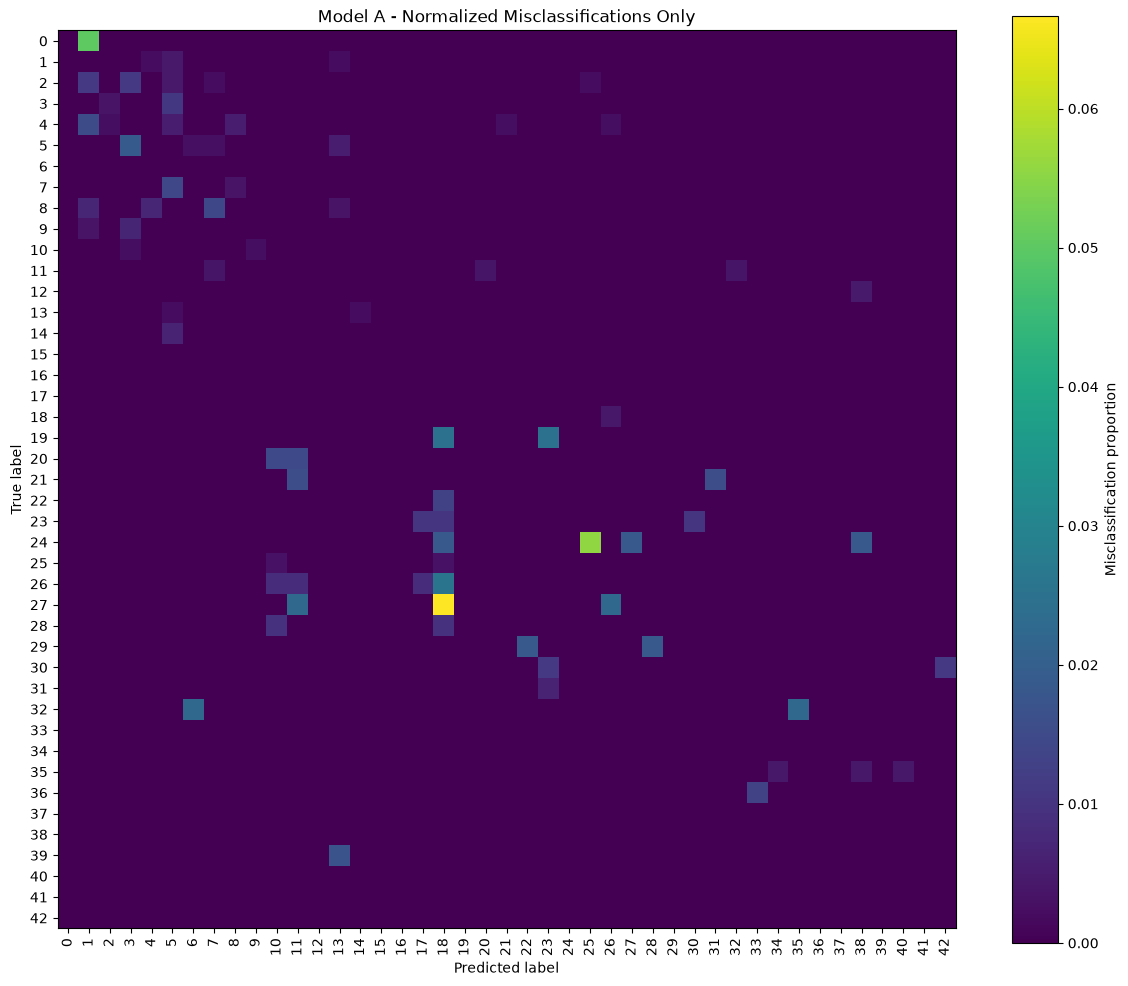

In [47]:
cm_errors = cm_norm.copy()

# Remove correct predictions
import numpy as np
np.fill_diagonal(cm_errors, 0)

plt.figure(figsize=(12, 10))

plt.imshow(cm_errors, interpolation="nearest")
plt.title("Model A - Normalized Misclassifications Only")

plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.xticks(range(43), range(43), rotation=90)
plt.yticks(range(43), range(43))

plt.colorbar(label="Misclassification proportion")

plt.tight_layout()
plt.show()

In [48]:
import numpy as np

cm_errors = cm_norm.copy()
np.fill_diagonal(cm_errors, 0)

# Find the 10 largest off-diagonal entries
flat_indices = np.argsort(cm_errors.ravel())[::-1]

print("Top confusion pairs:")
count = 0

for idx in flat_indices:
    true_class, predicted_class = np.unravel_index(idx, cm_errors.shape)
    value = cm_errors[true_class, predicted_class]

    if value == 0:
        break

    print(
        f"True {true_class:2d} → Predicted {predicted_class:2d}: "
        f"{value * 100:.2f}%"
    )

    count += 1
    if count == 10:
        break

Top confusion pairs:
True 27 → Predicted 18: 6.67%
True 24 → Predicted 25: 5.56%
True  0 → Predicted  1: 5.00%
True 26 → Predicted 18: 2.56%
True 19 → Predicted 18: 2.50%
True 19 → Predicted 23: 2.50%
True 27 → Predicted 11: 2.22%
True 32 → Predicted 35: 2.22%
True 27 → Predicted 26: 2.22%
True 32 → Predicted  6: 2.22%


## CNN Model A v2 

Added another conv layer

In [49]:
class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            3, 16,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            16, 32,
            kernel_size=3,
            padding=1
        )

        self.conv3 = nn.Conv2d(
            32, 64,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()

        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 43)

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x

Training

In [50]:
import torch
import torch.nn as nn
import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

model_improved = ImprovedCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_improved.parameters(),
    lr=0.001
)

Using: cpu


In [51]:
num_epochs = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_acc = 0.0
best_model_state = None

for epoch in range(num_epochs):

    # =====================================================
    # TRAINING
    # =====================================================
    model_improved.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model_improved(images)

        # Loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * images.size(0)

        # Predictions
        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = correct / total


    # =====================================================
    # VALIDATION
    # =====================================================
    model_improved.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_improved(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader.dataset)
    val_acc = correct / total


    # =====================================================
    # STORE RESULTS
    # =====================================================
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)


    # Save the best model according to validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model_improved.state_dict())


    print(
        f"Epoch {epoch+1:2d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch  1/20 | Train Loss: 1.8592 | Train Acc: 0.4500 | Val Loss: 0.7713 | Val Acc: 0.7499
Epoch  2/20 | Train Loss: 0.4647 | Train Acc: 0.8534 | Val Loss: 0.2153 | Val Acc: 0.9365
Epoch  3/20 | Train Loss: 0.2068 | Train Acc: 0.9370 | Val Loss: 0.1243 | Val Acc: 0.9649
Epoch  4/20 | Train Loss: 0.1233 | Train Acc: 0.9627 | Val Loss: 0.0966 | Val Acc: 0.9742
Epoch  5/20 | Train Loss: 0.0890 | Train Acc: 0.9731 | Val Loss: 0.0643 | Val Acc: 0.9835
Epoch  6/20 | Train Loss: 0.0698 | Train Acc: 0.9788 | Val Loss: 0.0585 | Val Acc: 0.9847
Epoch  7/20 | Train Loss: 0.0618 | Train Acc: 0.9807 | Val Loss: 0.0524 | Val Acc: 0.9879
Epoch  8/20 | Train Loss: 0.0540 | Train Acc: 0.9835 | Val Loss: 0.0664 | Val Acc: 0.9801
Epoch  9/20 | Train Loss: 0.0413 | Train Acc: 0.9870 | Val Loss: 0.0588 | Val Acc: 0.9864
Epoch 10/20 | Train Loss: 0.0429 | Train Acc: 0.9864 | Val Loss: 0.0493 | Val Acc: 0.9874
Epoch 11/20 | Train Loss: 0.0346 | Train Acc: 0.9891 | Val Loss: 0.0468 | Val Acc: 0.9902
Epoch 12/2

Training and Validation Curves

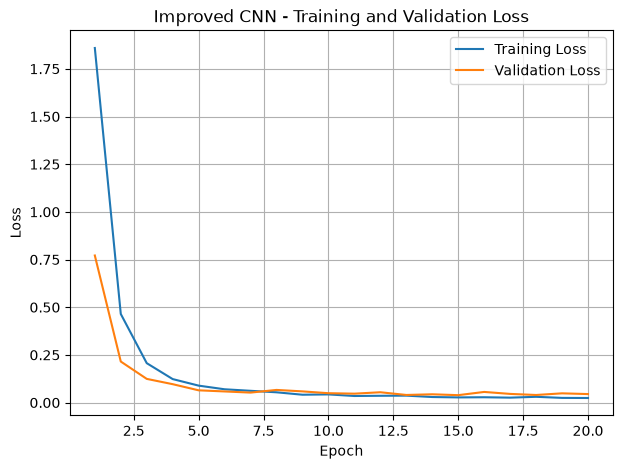

In [52]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(7, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved CNN - Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()

Accuracy

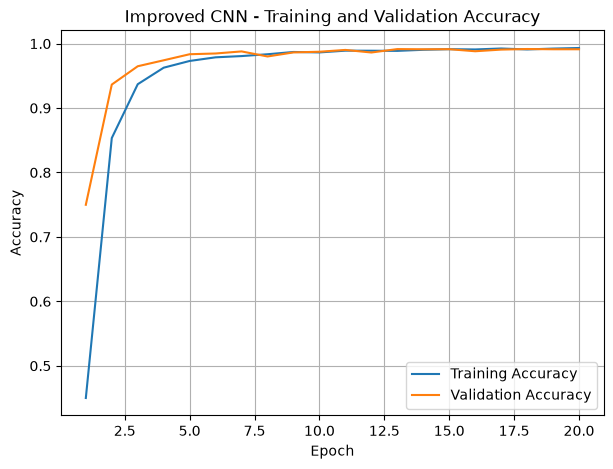

In [53]:
plt.figure(figsize=(7, 5))

plt.plot(epochs, train_accuracies, label="Training Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved CNN - Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

Test Eval

In [54]:
model_improved.eval()

test_loss = 0.0
correct = 0
total = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_improved(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

test_loss = test_loss / len(test_loader.dataset)
test_accuracy = correct / total

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss:     0.0444
Test Accuracy: 0.9896


In [55]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

weighted_precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

weighted_recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

weighted_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro"
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro"
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1:        {weighted_f1:.4f}")

print()

print(f"Macro Precision:    {macro_precision:.4f}")
print(f"Macro Recall:       {macro_recall:.4f}")
print(f"Macro F1:           {macro_f1:.4f}")

Weighted Precision: 0.9897
Weighted Recall:    0.9896
Weighted F1:        0.9896

Macro Precision:    0.9886
Macro Recall:       0.9883
Macro F1:           0.9883


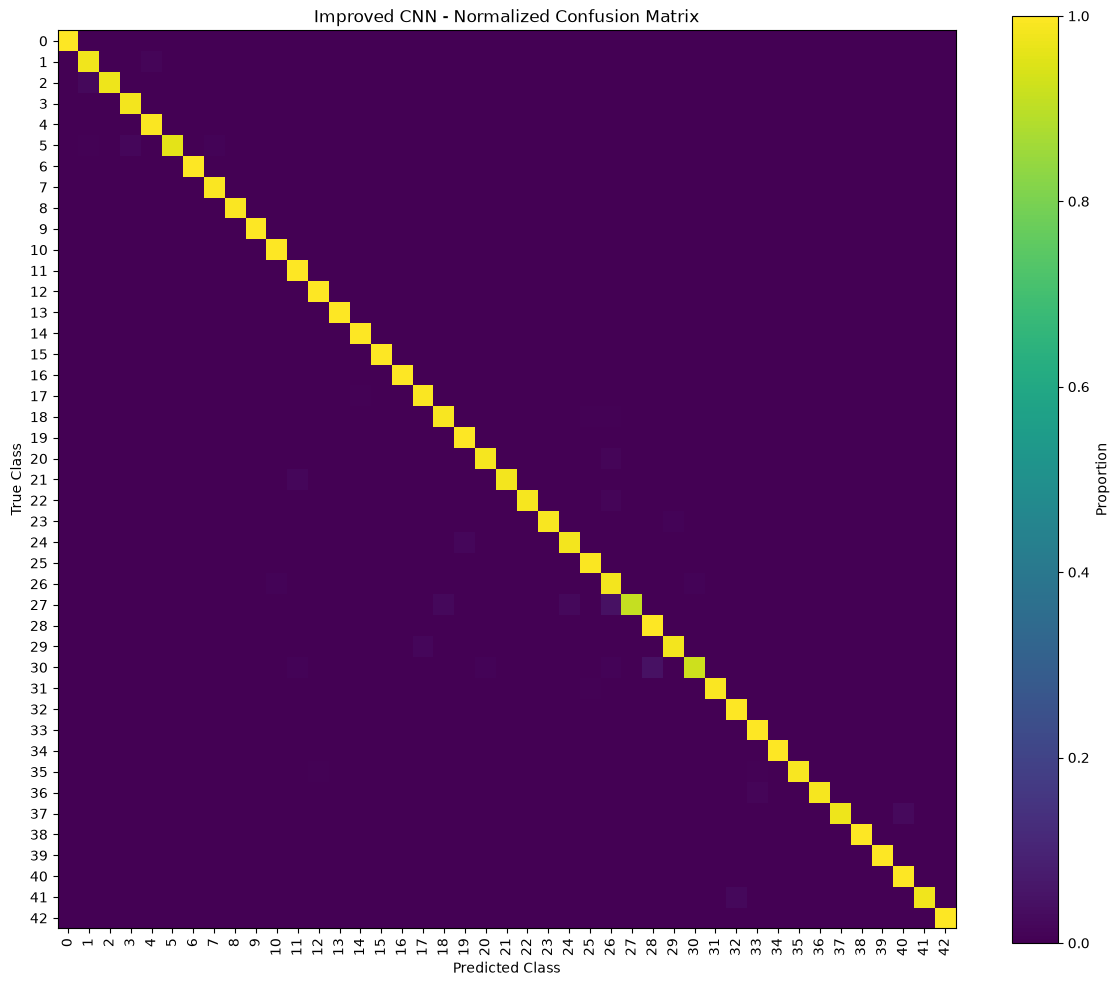

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_norm = confusion_matrix(
    all_labels,
    all_predictions,
    normalize="true"
)

plt.figure(figsize=(12, 10))

plt.imshow(cm_norm, interpolation="nearest")

plt.title("Improved CNN - Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(range(43), range(43), rotation=90)
plt.yticks(range(43), range(43))

plt.colorbar(label="Proportion")

plt.tight_layout()
plt.show()

In [57]:
total_params = sum(
    p.numel()
    for p in model_improved.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)

Trainable parameters: 160331


## Model B

##  ARCHITECTURE DEFINITION

Model B Trainable Parameters: 54,251
Epoch 01/20 | Train Loss: 1.8699, Acc: 0.4676 | Val Loss: 0.6550, Acc: 0.8138
Epoch 02/20 | Train Loss: 0.4154, Acc: 0.8830 | Val Loss: 0.1249, Acc: 0.9698
Epoch 03/20 | Train Loss: 0.1549, Acc: 0.9598 | Val Loss: 0.0616, Acc: 0.9844
Epoch 04/20 | Train Loss: 0.0967, Acc: 0.9747 | Val Loss: 0.0340, Acc: 0.9909
Epoch 05/20 | Train Loss: 0.0672, Acc: 0.9817 | Val Loss: 0.0280, Acc: 0.9920
Epoch 06/20 | Train Loss: 0.0575, Acc: 0.9832 | Val Loss: 0.0226, Acc: 0.9946
Epoch 07/20 | Train Loss: 0.0491, Acc: 0.9855 | Val Loss: 0.0166, Acc: 0.9958
Epoch 08/20 | Train Loss: 0.0435, Acc: 0.9874 | Val Loss: 0.0164, Acc: 0.9961
Epoch 09/20 | Train Loss: 0.0381, Acc: 0.9878 | Val Loss: 0.0143, Acc: 0.9963
Epoch 10/20 | Train Loss: 0.0338, Acc: 0.9894 | Val Loss: 0.0142, Acc: 0.9952
Epoch 11/20 | Train Loss: 0.0284, Acc: 0.9912 | Val Loss: 0.0122, Acc: 0.9972
Epoch 12/20 | Train Loss: 0.0305, Acc: 0.9912 | Val Loss: 0.0144, Acc: 0.9960
Epoch 13/20 | Train Loss: 0

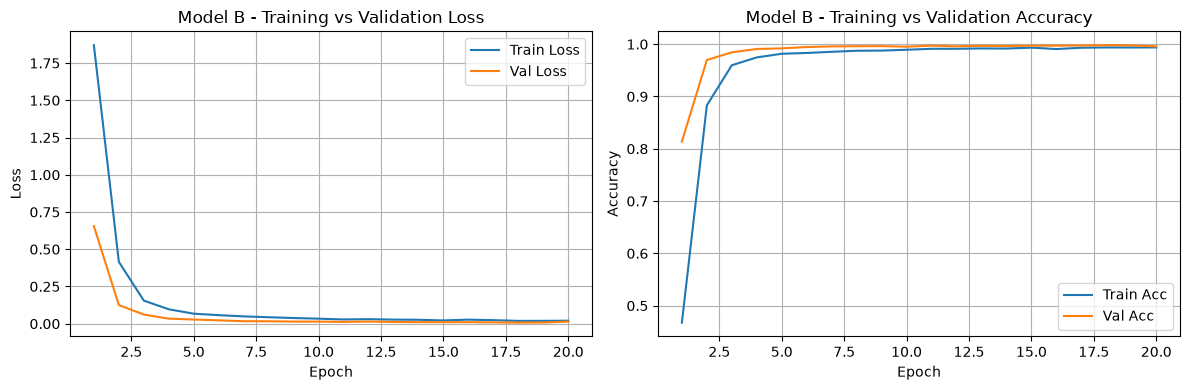


Test Loss: 0.0124
Test Accuracy: 99.5756%
Weighted Precision: 0.9958
Weighted Recall:    0.9958
Weighted F1-Score:  0.9958
Macro Precision:    0.9964
Macro Recall:       0.9948


In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        # Depthwise Conv (groups = in_channels)
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=stride, padding=1, groups=in_channels, bias=False)
        self.bn1 = nn.BatchNorm2d(in_channels)
        # Pointwise Conv (1x1)
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, padding=0, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.act = nn.ReLU6(inplace=True)

    def forward(self, x):
        return self.act(self.bn2(self.pointwise(self.act(self.bn1(self.depthwise(x))))))

class ModelB_LightweightCNN(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU6(inplace=True)
        )
        self.block1 = DepthwiseSeparableConv(32, 64)
        self.pool1 = nn.MaxPool2d(2, 2)
        
        self.block2 = DepthwiseSeparableConv(64, 128)
        self.pool2 = nn.MaxPool2d(2, 2)
        
        self.block3 = DepthwiseSeparableConv(128, 128)
        self.pool3 = nn.MaxPool2d(2, 2)
        
        self.block4 = DepthwiseSeparableConv(128, 128)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.25)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.block1(x))
        x = self.pool2(self.block2(x))
        x = self.pool3(self.block3(x))
        x = self.block4(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.fc(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_b = ModelB_LightweightCNN(num_classes=43).to(device)

print(f"Model B Trainable Parameters: {sum(p.numel() for p in model_b.parameters() if p.requires_grad):,}")



## TRAINING LOOP (20 EPOCHS)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_b.parameters(), lr=0.001)
num_epochs = 20

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(num_epochs):
    # Training phase
    model_b.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_b(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
        
    train_loss = running_loss / len(train_loader.dataset)
    train_acc = correct / total
    
    # Validation phase
    model_b.eval()
    val_loss_running, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_b(images)
            loss = criterion(outputs, labels)
            val_loss_running += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_total += labels.size(0)
            val_correct += (preds == labels).sum().item()
            
    val_loss = val_loss_running / len(val_loader.dataset)
    val_acc = val_correct / val_total
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    
    print(f"Epoch {epoch+1:02d}/{num_epochs} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")



## PLOTS (LOSS & ACCURACY)

In [ ]:
epochs = range(1, num_epochs + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, train_losses, label='Train Loss')
ax[0].plot(epochs, val_losses, label='Val Loss')
ax[0].set_title('Model B - Training vs Validation Loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].grid(True)
ax[0].legend()

ax[1].plot(epochs, train_accuracies, label='Train Acc')
ax[1].plot(epochs, val_accuracies, label='Val Acc')
ax[1].set_title('Model B - Training vs Validation Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()



## TEST SET EVALUATION & METRICS

In [ ]:
model_b.eval()
test_loss, correct, total = 0.0, 0, 0
all_labels, all_preds = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model_b(images)
        loss = criterion(outputs, labels)
        test_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

print(f"\nTest Loss: {test_loss/len(test_loader.dataset):.4f}")
print(f"Test Accuracy: {correct/total:.4%}")
print(f"Weighted Precision: {precision_score(all_labels, all_preds, average='weighted', zero_division=0):.4f}")
print(f"Weighted Recall:    {recall_score(all_labels, all_preds, average='weighted', zero_division=0):.4f}")
print(f"Weighted F1-Score:  {f1_score(all_labels, all_preds, average='weighted', zero_division=0):.4f}")
print(f"Macro Precision:    {precision_score(all_labels, all_preds, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:       {recall_score(all_labels, all_preds, average='macro', zero_division=0):.4f}")
